# HSV Experiment: Artistic Style Classification

This notebook investigates the classification performance of a
convolutional neural network (CNN) when painting images are
represented in the HSV colour space.

The experiment follows the same methodology, model architecture,
training configuration and evaluation procedure as the RGB baseline.

Only the input colour-space representation is changed.

## 1. Environment setup

Mount Google Drive and initialise access to the DeepLearning project.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

%cd /content/drive/MyDrive/DeepLearning

import sys
sys.path.insert(0, "/content/drive/MyDrive/DeepLearning")

from pathlib import Path
import pandas as pd
import tensorflow as tf

from src import config, data, models, training, evaluation
from src import visualization, experiment

print("Project environment ready!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/DeepLearning
Project environment ready!


## 2. Experiment configuration

Define the parameters for the HSV experiment.

The configuration is imported from the central project configuration
module to ensure consistency across colour-space experiments.

In [3]:
COLOR_SPACE = "hsv"
SEED = 42
EPOCHS = config.MAX_EPOCHS

print("HSV EXPERIMENT CONFIGURATION")
print("-" * 40)

print(f"Colour space: {COLOR_SPACE}")
print(f"Random seed: {SEED}")
print(f"Maximum epochs: {EPOCHS}")
print(f"Image size: {config.IMAGE_SIZE}")
print(f"Batch size: {config.BATCH_SIZE}")
print(f"Learning rate: {config.LEARNING_RATE}")
print(f"Classes: {config.CLASSES}")

HSV EXPERIMENT CONFIGURATION
----------------------------------------
Colour space: hsv
Random seed: 42
Maximum epochs: 30
Image size: (180, 180)
Batch size: 16
Learning rate: 0.001
Classes: ['monet', 'picasso', 'vangogh']


## 3. Dataset preparation

Load the prepared painting dataset using the HSV colour-space
representation.

The dataset is divided into training, validation and test sets.
The same dataset splits are retained across all colour-space
experiments to ensure a consistent comparison.

### 3.1 Load HSV datasets

Load the training, validation and test datasets using the
reusable data-loading pipeline.

Images are transformed from RGB to HSV before being passed
to the CNN.

In [4]:
train_dataset, validation_dataset, test_dataset = data.load_datasets(
    color_space=COLOR_SPACE,
    seed=SEED
)

print("HSV datasets loaded successfully.")

Found 210 files belonging to 3 classes.
Found 59 files belonging to 3 classes.
Found 30 files belonging to 3 classes.
HSV datasets loaded successfully.


### 3.2 Verify dataset sizes

Verify that the same number of images is available in each
dataset split as in the RGB experiment.

In [5]:
dataset_sizes = {
    "Training": 210,
    "Validation": 59,
    "Test": 30
}

for split_name, expected_size in dataset_sizes.items():
    print(f"{split_name}: {expected_size} images")

print(f"\nTotal images: {sum(dataset_sizes.values())}")

Training: 210 images
Validation: 59 images
Test: 30 images

Total images: 299


### 3.3 Inspect image and label shapes

Inspect a batch of HSV images and their corresponding labels.

The HSV representation retains three channels, allowing the
same CNN architecture to be used without modification.

In [6]:
images, labels = next(iter(train_dataset))

print("IMAGE INFORMATION")
print("-" * 40)
print("Image batch shape:", images.shape)
print("Image data type:", images.dtype)
print("Minimum pixel value:", float(tf.reduce_min(images)))
print("Maximum pixel value:", float(tf.reduce_max(images)))

print("\nLABEL INFORMATION")
print("-" * 40)
print("Label batch shape:", labels.shape)
print("Label data type:", labels.dtype)
print("Example label:", labels[0].numpy())

IMAGE INFORMATION
----------------------------------------
Image batch shape: (16, 180, 180, 3)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0

LABEL INFORMATION
----------------------------------------
Label batch shape: (16, 3)
Label data type: <dtype: 'float32'>
Example label: [0. 0. 1.]


### 3.4 Verify dataset pipeline

Verify the image dimensions, number of channels, label dimensions
and normalised pixel value range before proceeding to training.

In [7]:
assert images.shape[1:] == (
    config.IMAGE_SIZE[0],
    config.IMAGE_SIZE[1],
    3
)

assert labels.shape[1] == config.NUM_CLASSES

assert images.dtype == tf.float32
assert labels.dtype == tf.float32

assert float(tf.reduce_min(images)) >= 0.0
assert float(tf.reduce_max(images)) <= 1.0

assert train_dataset is not None
assert validation_dataset is not None
assert test_dataset is not None

print("HSV dataset pipeline verified successfully.")

HSV dataset pipeline verified successfully.


## 4. CNN model initialisation

Initialise the convolutional neural network (CNN) used for the
HSV experiment.

The same CNN architecture and hyperparameters used in the RGB
baseline are retained to ensure a controlled comparison between
colour-space representations.

### 4.1 Build the CNN

Build and compile the CNN using the reusable model implementation.

In [8]:
model = models.build_cnn()
model = models.compile_cnn(model)

print("HSV CNN model initialised successfully.")

HSV CNN model initialised successfully.


### 4.2 Inspect model architecture

Display the model architecture, including output shapes and
parameter counts for each layer.

The architecture should be identical to the RGB experiment.

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

### 4.3 Verify model configuration

Verify that the model accepts images with the expected dimensions
and produces three output probabilities, corresponding to the
three artistic styles.

The parameter count is compared against the RGB baseline.

In [10]:
print("MODEL CONFIGURATION")
print("-" * 40)

print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total parameters:", model.count_params())
print("Number of classes:", config.NUM_CLASSES)

assert model.input_shape == (
    None,
    config.IMAGE_SIZE[0],
    config.IMAGE_SIZE[1],
    config.IMAGE_CHANNELS
)

assert model.output_shape == (None, config.NUM_CLASSES)

assert model.count_params() == 110147

print("\nHSV model configuration verified successfully.")

MODEL CONFIGURATION
----------------------------------------
Input shape: (None, 180, 180, 3)
Output shape: (None, 3)
Total parameters: 110147
Number of classes: 3

HSV model configuration verified successfully.


### 4.4 Verify model compilation

Inspect the optimiser, learning rate and loss function to ensure
that the HSV experiment uses the same training configuration
as the RGB baseline.

In [11]:
print("MODEL TRAINING CONFIGURATION")
print("-" * 40)

print("Optimiser:", type(model.optimizer).__name__)

print(
    "Learning rate:",
    float(tf.keras.backend.get_value(model.optimizer.learning_rate))
)

print("Loss function:", model.loss)
print("Metrics:", model.metrics_names)

MODEL TRAINING CONFIGURATION
----------------------------------------
Optimiser: Adam
Learning rate: 0.0010000000474974513
Loss function: categorical_crossentropy
Metrics: ['loss', 'compile_metrics']


## 5. Model training

Train the CNN using the HSV representation of the painting dataset.

The training process uses the same parameters as the RGB baseline.
Early stopping monitors validation loss, while learning-rate
reduction adjusts the learning rate when validation performance
stops improving.

The best-performing model is saved using ModelCheckpoint.

### 5.1 Training configuration

Define the training parameters for the HSV experiment.

In [12]:
print("HSV TRAINING CONFIGURATION")
print("-" * 40)

print(f"Colour space: {COLOR_SPACE}")
print(f"Random seed: {SEED}")
print(f"Maximum epochs: {EPOCHS}")
print(f"Early stopping patience: {config.EARLY_STOPPING_PATIENCE}")
print(f"Learning rate: {config.LEARNING_RATE}")
print(f"Batch size: {config.BATCH_SIZE}")
print(f"Dropout rate: {config.DROPOUT_RATE}")

HSV TRAINING CONFIGURATION
----------------------------------------
Colour space: hsv
Random seed: 42
Maximum epochs: 30
Early stopping patience: 6
Learning rate: 0.001
Batch size: 16
Dropout rate: 0.4


### 5.2 Train the CNN

Train the CNN using the HSV training dataset and monitor its
performance on the validation dataset.

The training function handles random seed initialisation,
callback configuration, model checkpointing and training-history
persistence.

The model returned by the function is the best model checkpoint,
selected according to validation loss.

In [13]:
hsv_model, hsv_history, training_metadata = training.train_model(
    train_dataset=train_dataset,
    validation_dataset=validation_dataset,
    color_space=COLOR_SPACE,
    seed=SEED,
    epochs=EPOCHS
)

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.4194 - loss: 1.0898
Epoch 1: val_loss improved from None to 1.05670, saving model to /content/drive/MyDrive/DeepLearning/outputs/models/hsv_seed42.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DeepLearning/outputs/models/hsv_seed42.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 103s 7s/step - accuracy: 0.3952 - loss: 1.0866 - val_accuracy: 0.3390 - val_loss: 1.0567 - learning_rate: 0.0010
Epoch 2/30
13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - accuracy: 0.3947 - loss: 1.0782
Epoch 2: val_loss improved from 1.05670 to 0.98156, saving model to /content/drive/MyDrive/DeepLearning/outputs/models/hsv_seed42.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DeepLearning/outputs/models/hsv_seed42.keras
14/14 ━━━━━━━━━━━━━━━━━━━━ 4s 295ms/step - accuracy: 0.4571 - loss: 1.0513 - val_accuracy: 0.5254 - val_loss: 0.9816 - learning_rate: 0.0010
Epoch 3/30
13/14 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.5321 - lo

### 5.3 Inspect training metadata

Inspect the training metadata returned by the training function.

This includes the number of completed epochs, the epoch with
the lowest validation loss, training duration, model parameter
count and saved model location.

In [14]:
print("HSV TRAINING RESULTS")
print("-" * 40)

print("Colour space:", training_metadata["color_space"])
print("Random seed:", training_metadata["seed"])
print("Epochs completed:", training_metadata["epochs_completed"])
print("Best epoch:", training_metadata["best_epoch"])

print(
    "Training time:",
    f'{training_metadata["training_time_seconds"]:.2f} seconds'
)

print("Model parameters:", training_metadata["parameter_count"])
print("Saved model:", training_metadata["model_path"])
print("Saved history:", training_metadata["history_path"])

HSV TRAINING RESULTS
----------------------------------------
Colour space: hsv
Random seed: 42
Epochs completed: 30
Best epoch: 30
Training time: 190.90 seconds
Model parameters: 110147
Saved model: /content/drive/MyDrive/DeepLearning/outputs/models/hsv_seed42.keras
Saved history: /content/drive/MyDrive/DeepLearning/outputs/metrics/hsv_seed42_history.csv


### 5.4 Verify training artefacts

Verify that the trained HSV model and training history have
been saved successfully.

These artefacts will be used for subsequent evaluation and
comparison with the RGB experiment.

In [15]:
model_path = Path(training_metadata["model_path"])
history_path = Path(training_metadata["history_path"])

assert model_path.exists(), "Saved HSV model could not be found."
assert history_path.exists(), "HSV training history could not be found."

print("HSV training artefacts verified successfully.")

print(
    "Model file size:",
    f"{model_path.stat().st_size / 1024**2:.2f} MB"
)

print(
    "History file size:",
    f"{history_path.stat().st_size / 1024:.2f} KB"
)

HSV training artefacts verified successfully.
Model file size: 1.31 MB
History file size: 2.90 KB


## 6. Training performance visualisation

Visualise the training process using the recorded training history.

Training and validation accuracy and loss are examined to
understand how the model learned and whether its performance
generalised to unseen validation data.

### 6.1 Training and validation performance

Plot training and validation accuracy and loss across epochs.

The accuracy plot illustrates classification performance,
while the loss plot provides insight into the optimisation
process and potential overfitting.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/training_curves_hsv_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/training_curves_hsv_seed42.pdf


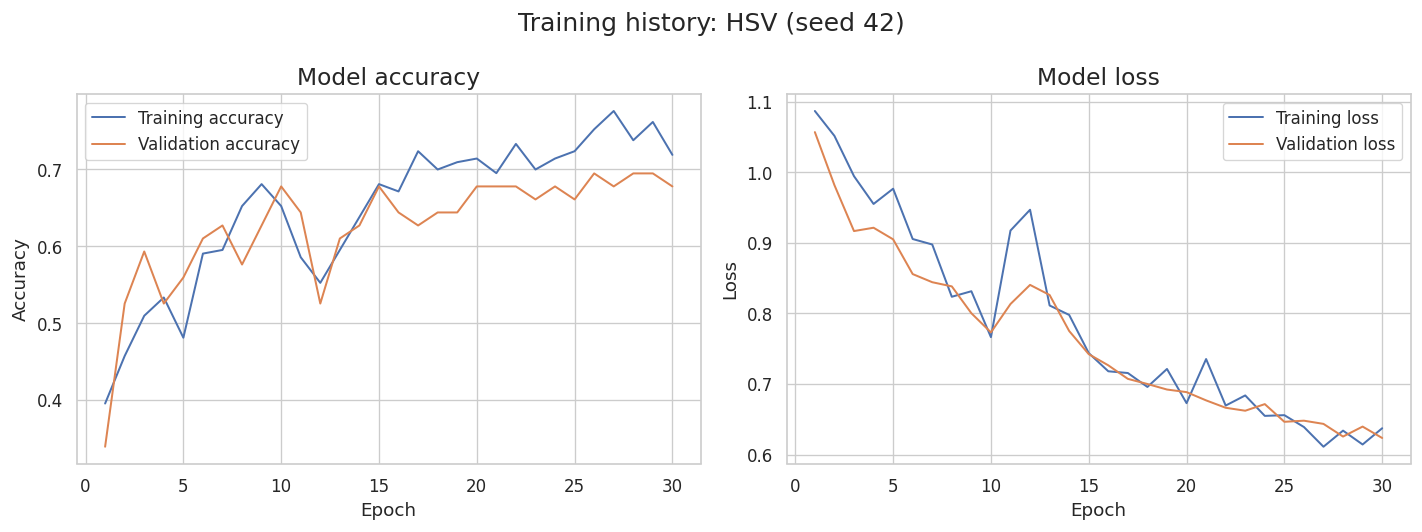

In [16]:
training_figure = visualization.plot_training_history(
    history=hsv_history,
    color_space=COLOR_SPACE,
    seed=SEED
)

### 6.2 Inspect training history

Inspect the recorded training metrics to identify the best
validation performance and the final training and validation
metrics.

In [17]:
history_df = pd.read_csv(training_metadata["history_path"])

print("HSV TRAINING HISTORY")
print("-" * 60)

display(history_df.head())

best_val_loss_epoch = history_df["val_loss"].idxmin()
best_val_accuracy_epoch = history_df["val_accuracy"].idxmax()

print("\nBEST VALIDATION PERFORMANCE")
print("-" * 60)

print(
    f"Lowest validation loss: "
    f"{history_df.loc[best_val_loss_epoch, 'val_loss']:.4f} "
    f"(epoch {best_val_loss_epoch + 1})"
)

print(
    f"Highest validation accuracy: "
    f"{history_df.loc[best_val_accuracy_epoch, 'val_accuracy']:.4f} "
    f"(epoch {best_val_accuracy_epoch + 1})"
)

HSV TRAINING HISTORY
------------------------------------------------------------


,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.395238,1.086606,0.338983,1.056700,0.001
1,0.457143,1.051347,0.525424,0.981564,0.001
2,0.509524,0.994280,0.593220,0.916517,0.001
3,0.533333,0.954933,0.525424,0.921228,0.001
4,0.480952,0.976522,0.559322,0.904801,0.001



BEST VALIDATION PERFORMANCE
------------------------------------------------------------
Lowest validation loss: 0.6234 (epoch 30)
Highest validation accuracy: 0.6949 (epoch 26)


### 6.3 Verify saved training figures

Verify that the HSV training performance figures have been
saved in both PNG and PDF formats.

The figures are stored in the project output directory and
the report directory for later use in the research paper.

In [18]:
figure_directory = Path(config.FIGURES_DIR)
report_figure_directory = Path(config.REPORT_FIGURES_DIR)

expected_files = [
    f"training_curves_{COLOR_SPACE}_seed{SEED}.png",
    f"training_curves_{COLOR_SPACE}_seed{SEED}.pdf"
]

print("HSV TRAINING FIGURES")
print("-" * 40)

for filename in expected_files:
    output_file = figure_directory / filename
    report_file = report_figure_directory / filename

    assert output_file.exists(), f"Missing output figure: {filename}"
    assert report_file.exists(), f"Missing report figure: {filename}"

    print(f"Verified: {filename}")

print("\nAll HSV training figures verified successfully.")

HSV TRAINING FIGURES
----------------------------------------
Verified: training_curves_hsv_seed42.png
Verified: training_curves_hsv_seed42.pdf

All HSV training figures verified successfully.


## 7. Test-set evaluation

Evaluate the best-performing HSV CNN using the held-out test set.

The test set has not been used during model training or checkpoint
selection. It provides an independent assessment of classification
performance.

The evaluation includes accuracy, macro-averaged precision,
recall and F1-score, as well as class-specific performance.

### 7.1 Evaluate the trained model

Evaluate the best HSV model using the test dataset.

The evaluation function calculates classification metrics and
generates predictions for subsequent analysis.

In [19]:
hsv_evaluation = evaluation.evaluate_model(
    model=hsv_model,
    test_dataset=test_dataset,
    color_space=COLOR_SPACE
)

print("HSV test-set evaluation completed.")

HSV test-set evaluation completed.


### 7.2 Overall classification performance

Inspect the overall classification metrics calculated on the
held-out test set.

Macro-averaged precision, recall and F1-score give equal weight
to each artistic style when calculating the overall metrics.

In [20]:
hsv_summary = hsv_evaluation["summary"]

print("HSV CLASSIFICATION PERFORMANCE")
print("-" * 45)

for metric, value in hsv_summary.items():
    print(f"{metric}: {value}")

HSV CLASSIFICATION PERFORMANCE
---------------------------------------------
color_space: hsv
seed: 42
accuracy: 0.7
macro_precision: 0.6956043956043955
macro_recall: 0.7000000000000001
macro_f1: 0.6887468030690537
test_loss: 0.6458396315574646
test_accuracy: 0.699999988079071


### 7.3 Class-specific performance

Inspect the classification report to examine how well the
model distinguishes between Monet, Picasso and Van Gogh.

Precision measures the proportion of predictions for a class
that are correct, while recall measures the proportion of
actual instances of that class that are correctly identified.

The F1-score combines precision and recall.

In [21]:
hsv_class_report = hsv_evaluation["class_report"]

display(hsv_class_report)

,precision,recall,f1-score,support
monet,0.615385,0.8,0.695652,10.0
picasso,0.900000,0.9,0.900000,10.0
vangogh,0.571429,0.4,0.470588,10.0
accuracy,0.700000,0.7,0.700000,0.7
macro avg,0.695604,0.7,0.688747,30.0
weighted avg,0.695604,0.7,0.688747,30.0


### 7.4 Confusion matrix

Generate a confusion matrix to examine the distribution of
correct and incorrect predictions across the three artistic
styles.

The diagonal represents correct classifications, while
off-diagonal values represent misclassifications.

In [22]:
hsv_confusion_matrix = hsv_evaluation["confusion_matrix"]

print("HSV CONFUSION MATRIX")
print("-" * 40)

display(
    pd.DataFrame(
        hsv_confusion_matrix,
        index=config.CLASSES,
        columns=config.CLASSES
    )
)

HSV CONFUSION MATRIX
----------------------------------------


,monet,picasso,vangogh
monet,8,0,2
picasso,0,9,1
vangogh,5,1,4


Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/confusion_matrix_hsv_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/confusion_matrix_hsv_seed42.pdf


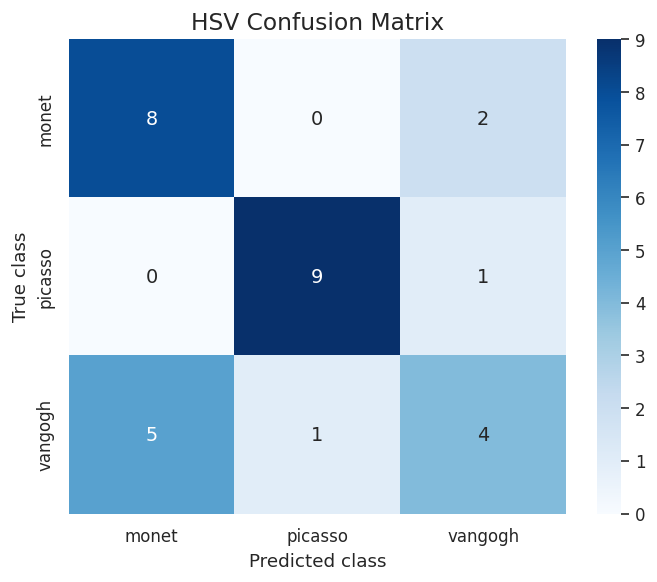

In [23]:
visualization.plot_confusion_matrix(
    confusion_matrix=hsv_confusion_matrix,
    color_space=COLOR_SPACE,
    seed=SEED
)

### 7.5 Class-specific metric visualisation

Visualise precision, recall and F1-score for each artistic
style to identify differences in classification performance
between the classes.

Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/class_metrics_hsv_seed42.png
Saved: /content/drive/MyDrive/DeepLearning/outputs/figures/class_metrics_hsv_seed42.pdf


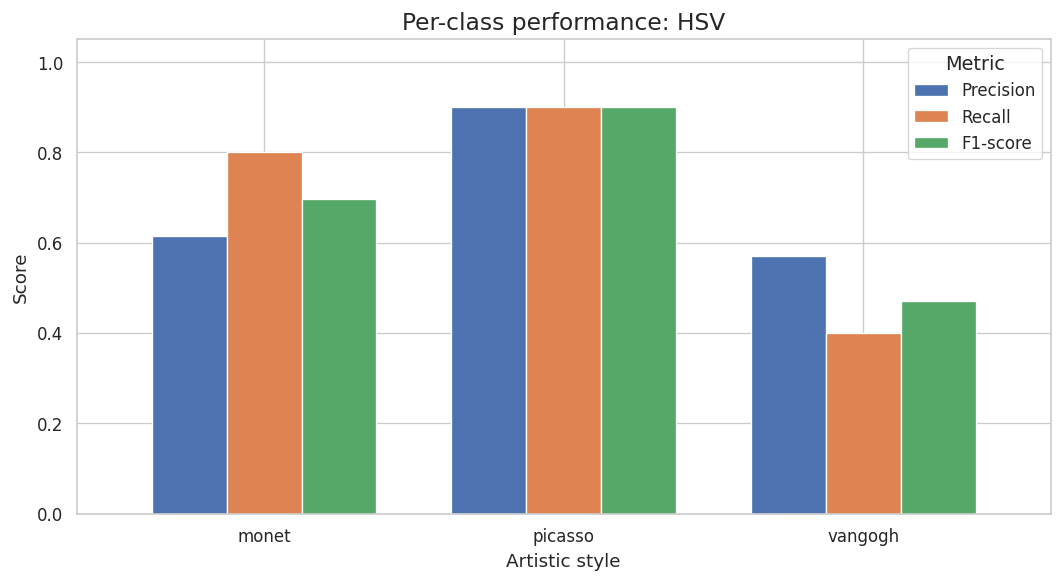

In [24]:
visualization.plot_class_metrics(
    class_report=hsv_class_report,
    color_space=COLOR_SPACE,
    seed=SEED
)

### 7.6 Save evaluation results

Save the HSV evaluation results to the project output directory.

The saved artefacts include the overall evaluation metrics,
classification report, confusion matrix and individual predictions.
These files will support the comparison between colour-space
representations.

In [25]:
evaluation.save_evaluation_results(
    results=hsv_evaluation,
    color_space=COLOR_SPACE,
    seed=SEED
)

print("HSV evaluation results saved successfully.")

HSV evaluation results saved successfully.


In [26]:
expected_evaluation_files = [
    f"{COLOR_SPACE}_seed{SEED}_evaluation.json",
    f"{COLOR_SPACE}_seed{SEED}_classification_report.csv",
    f"{COLOR_SPACE}_seed{SEED}_confusion_matrix.csv",
    f"{COLOR_SPACE}_seed{SEED}_predictions.csv"
]

print("HSV EVALUATION ARTEFACTS")
print("-" * 45)

for filename in expected_evaluation_files:
    file_path = Path(config.METRICS_DIR) / filename

    assert file_path.exists(), f"Missing evaluation artefact: {filename}"

    print(f"Verified: {filename}")

print("\nAll HSV evaluation artefacts verified successfully.")

HSV EVALUATION ARTEFACTS
---------------------------------------------
Verified: hsv_seed42_evaluation.json
Verified: hsv_seed42_classification_report.csv
Verified: hsv_seed42_confusion_matrix.csv
Verified: hsv_seed42_predictions.csv

All HSV evaluation artefacts verified successfully.


## 8. HSV experiment results

Consolidate the HSV experiment results into a structured summary.

The summary combines training information and test-set
classification metrics, providing a single record of the
experiment for subsequent cross-colour-space comparison.

In [27]:
hsv_results = {
    "color_space": COLOR_SPACE,
    "seed": SEED,
    "epochs_completed": training_metadata["epochs_completed"],
    "best_epoch": training_metadata["best_epoch"],
    "training_time_seconds": training_metadata["training_time_seconds"],
    "parameter_count": training_metadata["parameter_count"],
    **hsv_evaluation["summary"]
}

hsv_results_df = pd.DataFrame([hsv_results])

display(hsv_results_df)

,color_space,seed,epochs_completed,best_epoch,training_time_seconds,parameter_count,accuracy,macro_precision,macro_recall,macro_f1,test_loss,test_accuracy
0,hsv,42,30,30,190.902518,110147,0.7,0.695604,0.7,0.688747,0.64584,0.7


### 8.1 Save experiment summary

Save the consolidated HSV experiment results as a CSV file.

This file will later be combined with the corresponding
summaries from the RGB and grayscale experiments.

In [28]:
 hsv_summary_path = (
    Path(config.METRICS_DIR) /
    f"{COLOR_SPACE}_seed{SEED}_experiment_summary.csv"
)

hsv_results_df.to_csv(hsv_summary_path, index=False)

print("Saved:", hsv_summary_path)

Saved: /content/drive/MyDrive/DeepLearning/outputs/metrics/hsv_seed42_experiment_summary.csv


### 8.2 Inspect experiment artefacts

Inspect the files generated during the HSV experiment.

These include the trained model, training history, evaluation
metrics, classification report, confusion matrix, predictions
and visualisations.

In [29]:
artifact_directories = {
    "Model": config.MODELS_DIR,
    "Metrics": config.METRICS_DIR,
    "Figures": config.FIGURES_DIR
}

for category, directory in artifact_directories.items():
    print(f"\n{category.upper()}")
    print("-" * 45)

    matching_files = sorted(
        Path(directory).glob(f"*{COLOR_SPACE}*seed{SEED}*")
    )

    for file_path in matching_files:
        if file_path.is_file():
            print(file_path.name)


MODEL
---------------------------------------------
hsv_seed42.keras

METRICS
---------------------------------------------
hsv_seed42_classification_report.csv
hsv_seed42_confusion_matrix.csv
hsv_seed42_evaluation.json
hsv_seed42_experiment_summary.csv
hsv_seed42_history.csv
hsv_seed42_predictions.csv

FIGURES
---------------------------------------------
class_metrics_hsv_seed42.pdf
class_metrics_hsv_seed42.png
confusion_matrix_hsv_seed42.pdf
confusion_matrix_hsv_seed42.png
training_curves_hsv_seed42.pdf
training_curves_hsv_seed42.png


### 8.3 HSV experiment record

The HSV experiment provides a second experimental condition
for investigating the influence of colour-space representation
on artistic style classification.

The same dataset split, CNN architecture, training configuration
and evaluation procedure are retained from the RGB baseline.

In [30]:
assert hsv_summary_path.exists()

print("HSV EXPERIMENT COMPLETED")
print("=" * 45)
print(f"Colour space: {COLOR_SPACE.upper()}")
print(f"Random seed: {SEED}")
print(f"Best epoch: {training_metadata['best_epoch']}")
print(
    f"Test accuracy: "
    f"{hsv_evaluation['summary']['accuracy']:.4f}"
)
print(f"Experiment summary: {hsv_summary_path}")

HSV EXPERIMENT COMPLETED
Colour space: HSV
Random seed: 42
Best epoch: 30
Test accuracy: 0.7000
Experiment summary: /content/drive/MyDrive/DeepLearning/outputs/metrics/hsv_seed42_experiment_summary.csv
